# Bonus B6: How to move retrieval to Pinecone

**Notebook 2 of 2: Pinecone at the Chinook support desk**

This is a bonus lab and it needs a Pinecone account; the free Starter plan is enough. Retrieval itself needs no
account: Lab 12 teaches it with Chroma, which runs inside the notebook.

## Goal

Move the Chinook support desk's search from Chroma to Pinecone, and find out what the move changes. We embed the
shop's 36 policy and ticket files once, and give the same vectors to a Chroma collection in this notebook and to a
Pinecone index in your account. Then a rep asks *When is support staffed?* In Chroma the file with the hours comes
second, behind the file about the support staff. We ask Pinecone the same question and compare the two rankings,
and then read what the rep gets back when only the nearest file reaches the model. At the end we say what the move
changed and what it left alone, and delete the index.

## What you will learn

- How to load the same vectors into a Chroma collection and a Pinecone index, and check that both hold the same
  records.
- How to ask two stores one question and compare their rankings, and what an equal ranking establishes.
- How to tell a search that ranked the wrong file first from a problem with the store.
- How to write a Chroma `where` filter as a Pinecone `filter`, and which Pinecone call replaces which Chroma call.
- When a managed store is worth an account, and how to delete the index and check that it is gone.

## What this notebook uses from notebook 1

Notebook 1 introduces Pinecone with six recipe cards. This notebook restates what it uses from there, so it runs
on its own:

- An **index** is one searchable table of records in a Pinecone account. It is created with a name, a **schema**
  (here one vector field) and a deployment (who runs it, and where).
- A record is a **document**: a dictionary with an `_id`, the vector field, and any other keys we add.
- `upsert` writes documents (update or insert, by `_id`), and `search` returns the nearest ones for a vector, each
  with a `_score`. The score is the **cosine similarity**: 1 for vectors that point the same way, 0 for nothing in
  common, so bigger is nearer.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model names from `models.env`, and
takes the keys from `.env` without printing them. This lab adds two lines for `PINECONE_API_KEY`.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The keys come from the environment or .env, and are never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."
os.environ.setdefault("PINECONE_API_KEY", local.get("PINECONE_API_KEY") or "")
assert os.environ["PINECONE_API_KEY"], "Put PINECONE_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")
print("Pinecone key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes
Pinecone key found: yes


Two clients. OpenAI makes the vectors and writes the replies, with a 60-second limit on each request. Pinecone
stores and searches the vectors: `Pinecone()` reads `PINECONE_API_KEY` from the environment. Every chat call passes
`reasoning_effort=EFFORT or omit` (`omit` leaves the argument out when `models.env` sets no effort).

In [2]:
import time
import chromadb
from openai import OpenAI, omit
from pinecone import Pinecone, DenseVectorQuery

client = OpenAI(timeout=60)
pc = Pinecone()
EMBEDDING_MODEL = settings["EMBEDDING_MODEL"]

---

## Part A: Embed the shop's files once

The desk works from 36 Markdown files in `data/corpus/`: policies (the shop's rules) and tickets (cases where a
rule was applied). We read them in place and never change them. The part of each file name before the first
underscore is its kind, `policy` or `ticket`.

In [3]:
CORPUS = ROOT / "data" / "corpus"
files = sorted(CORPUS.glob("*.md"))
names = [p.name for p in files]
texts = [p.read_text() for p in files]
kinds = [name.split("_")[0] for name in names]

print(len(files), "files:", kinds.count("policy"), "policies,", kinds.count("ticket"), "tickets")
print(names[:3], "...")

36 files: 20 policies, 16 tickets
['policy_accounts.md', 'policy_cancellations.md', 'policy_damaged_media.md'] ...


`names`, `texts` and `kinds` come from the same sorted list of files, so position `i` in one belongs to position
`i` in the others. Here is the file this notebook keeps coming back to, as a rep would read it:

In [4]:
print(texts[names.index("policy_support_hours.md")])

# Support hours and SLA

Support is staffed Monday to Friday, 09:00 to 17:00 in the shop's local time. Closed public holidays.

First reply: within 1 business day.

Refund or replacement decision: within 3 business days of the first reply.

Urgent: damaged media that will not play, or a failed digital download. Those jump the queue.



The first line under the heading answers *When is support staffed?*: Monday to Friday, 09:00 to 17:00.

An **embedding model** turns a text into a **vector**, a list of numbers, and texts close in meaning get vectors
that point in similar directions. `input` takes a list of texts and returns one vector per text, in the same order.
We embed the 36 files in one call, and we do it once: both stores will get these same vectors.

In [5]:
response = client.embeddings.create(model=EMBEDDING_MODEL, input=texts)
vectors = [item.embedding for item in response.data]

print(len(vectors), "vectors of", len(vectors[0]), "numbers")
print("tokens read:", response.usage.prompt_tokens)

36 vectors of 1536 numbers
tokens read: 2551


36 vectors, one per file, each of 1,536 numbers. This is the only time the files are embedded. A vector store does
not make vectors unless we ask it to: OpenAI embeds, and the store keeps and ranks what it is given.

That gives us a fair test. If two stores hold the same vectors and are asked with the same question vector, any
difference in their answers comes from the store.

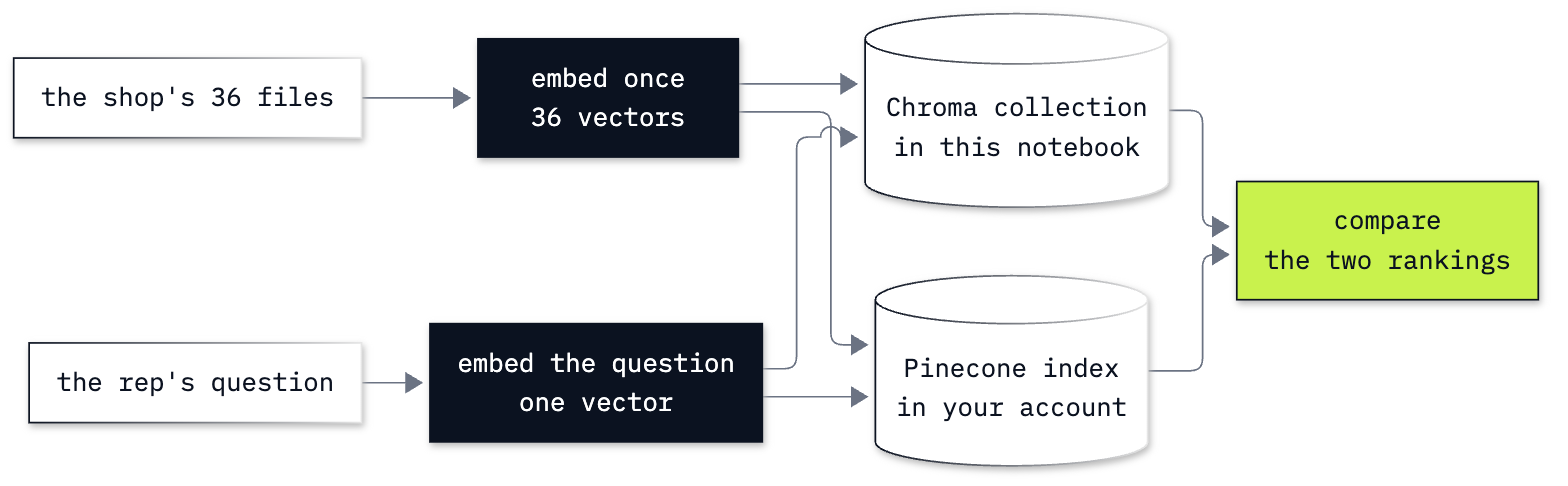

In [6]:
from IPython.display import Image

Image("resources/labB6_same_vectors_two_stores.png", width=760)

The black boxes are calls to the embedding model. The lime box is our code. The white shapes are data and the two
stores: one inside this notebook, one in your Pinecone account.

**Checkpoint A.** 36 files, 20 policies and 16 tickets; the hours file with its Monday to Friday line; 36 vectors
of 1,536 numbers.

---

## Part B: Store the same vectors in Chroma and in Pinecone

### Chroma, inside this notebook

**Chroma** is an open-source vector store that runs inside our Python process. A **collection** is its table of
records. A record has an id, a text, a vector, and **metadata**, labels we choose: here the `kind`. They are passed
as four lists in the same order. `"space": "cosine"` asks Chroma to rank by cosine similarity.

In [7]:
chroma = chromadb.EphemeralClient()
collection = chroma.get_or_create_collection("shop_files", configuration={"hnsw": {"space": "cosine"}})
collection.upsert(ids=names, documents=texts, metadatas=[{"kind": kind} for kind in kinds], embeddings=vectors)

print("in Chroma:", collection.count())

in Chroma: 36


36 records, in this process's memory. `EphemeralClient` keeps nothing on disk: restart the kernel and the
collection is gone.

### Pinecone, in your account

The same three steps on Pinecone: make the table, build the records, write them. First the index. Its schema has
one vector field, `embedding`, whose `dimension` is the length of our vectors and whose `metric` is `cosine`, the
same ranking we asked of Chroma. `us-east-1` on `aws` is the one region the free Starter plan allows. `create`
returns when the index is ready, and the `exists` check makes the cell safe to run twice.

In [8]:
INDEX_NAME = "ai-agents-b6-shop"

if not pc.indexes.exists(INDEX_NAME):
    pc.indexes.create(
        name=INDEX_NAME,
        schema={"fields": {"embedding": {"type": "dense_vector", "dimension": len(vectors[0]), "metric": "cosine"}}},
        deployment={"deployment_type": "managed", "cloud": "aws", "region": "us-east-1"},
    )

index = pc.index(INDEX_NAME)

print("exists:", pc.indexes.exists(INDEX_NAME))

exists: True


`pc` creates and deletes indexes; `index` reads and writes the records of this one.

Chroma took four lists. Pinecone takes one list of documents, each a dictionary that holds its own id (`_id`), its
vector (under the schema's field name, `embedding`), and its text and kind as extra keys. `zip` walks the four
lists together, so each document is built from one position of each.

Every write and every search names a **namespace**, a named section inside the index. We use one, `shop`.

In [9]:
documents = []
for name, vector, text, kind in zip(names, vectors, texts, kinds):
    documents.append({"_id": name, "embedding": vector, "text": text, "kind": kind})

written = index.documents.upsert(namespace="shop", documents=documents)
print("upserted:", written.upserted_count)

upserted: 36


`upserted: 36` says that Pinecone accepted the documents. Pinecone applies writes in the background, and its
documentation warns that a search sent straight after a write may not see the new records yet. So we ask the index
for the record count of the namespace, and wait until it is 36. `stored` returns 0 while the namespace is not there
yet.

In [10]:
def stored(namespace):
    spaces = index.describe_index_stats().namespaces
    return spaces[namespace].vector_count if namespace in spaces else 0


while stored("shop") < len(documents):
    time.sleep(1)

print("in Pinecone:", stored("shop"))

in Pinecone: 36


36 in Pinecone too. In our runs the count was right at the first look, so the loop never slept; it stays in the
code because a search that comes too early returns fewer files and raises no error.

### Check one record in both stores

Before comparing searches, we check that the two stores hold the same thing. `get` (Chroma) and `fetch` (Pinecone)
read a record by its id, with no search.

In [11]:
in_c = collection.get(ids=["policy_support_hours.md"], include=["metadatas", "documents"])
in_p = index.documents.fetch(namespace="shop", ids=["policy_support_hours.md"], include_fields=["kind", "text"])
record = in_p.documents["policy_support_hours.md"]

print("Chroma:  ", in_c["metadatas"][0], "|", in_c["documents"][0].splitlines()[2])
print("Pinecone:", {"kind": record.kind}, "|", record.text.splitlines()[2])

Chroma:   {'kind': 'policy'} | Support is staffed Monday to Friday, 09:00 to 17:00 in the shop's local time. Closed public holidays.
Pinecone: {'kind': 'policy'} | Support is staffed Monday to Friday, 09:00 to 17:00 in the shop's local time. Closed public holidays.


The same kind and the same hours line from both (`splitlines()[2]` is the file's third line: the heading, a blank
line, then the hours). The two results are shaped differently: Chroma returns one list per field, Pinecone one
document per id.

### See the index in the console

Open the Pinecone console at [app.pinecone.io](https://app.pinecone.io/), sign in, and find `ai-agents-b6-shop`
among your project's indexes. Look for the namespace `shop` and its 36 records, with the file names as ids.

*Screenshot to add: the Pinecone console with the index `ai-agents-b6-shop` open and the 36 records of the namespace `shop`.*

**Checkpoint B.** `in Chroma: 36`, `exists: True`, `upserted: 36`, `in Pinecone: 36`, and the same kind and hours
line from both stores.

---

## Part C: Ask both stores the same question

*When is support staffed?* We embed the question once and send the same vector to both stores. That matters: the
same text embedded twice can differ in the last decimals, and we want the stores to be the only difference.

First the ids and numbers from each raw result, before any helper.

In [12]:
STAFFED = "When is support staffed?"
q = client.embeddings.create(model=EMBEDDING_MODEL, input=STAFFED).data[0].embedding

from_chroma = collection.query(query_embeddings=[q], n_results=3)
from_pinecone = index.documents.search(
    namespace="shop",
    top_k=3,
    score_by=[DenseVectorQuery(field="embedding", values=q)],
    include_fields=["text"],
)

print("Chroma ids:      ", from_chroma["ids"][0])
print("Chroma distances:", [round(d, 4) for d in from_chroma["distances"][0]])
print("Pinecone:        ", [(match.id, round(match.score, 4)) for match in from_pinecone.matches])

Chroma ids:       ['policy_support_reps.md', 'policy_support_hours.md', 'policy_escalations.md']
Chroma distances: [0.4724, 0.5262, 0.6107]
Pinecone:         [('policy_support_reps.md', 0.5276), ('policy_support_hours.md', 0.4738), ('policy_escalations.md', 0.3893)]


The two calls say the same thing in different words:

| | Chroma | Pinecone |
|---|---|---|
| the question | `query_embeddings=[q]`, a list of vectors | `score_by=[DenseVectorQuery(field="embedding", values=q)]` |
| how many | `n_results=3` | `top_k=3` |
| the result | a dictionary of lists, one inner list per question: `ids`, `distances`, `documents` (`from_chroma["ids"][0]` is the list for our one question) | `matches`, one object per file, with `.id`, `.score` and our fields |
| the number | a **distance**, `1 − cosine`: smaller is nearer | a **score**, the cosine: bigger is nearer |

So to compare them we turn Chroma's distance back into a cosine: `1 - distance`.

In [13]:
print(f"{'Chroma':41} Pinecone")
for file_id, distance, match in zip(from_chroma["ids"][0], from_chroma["distances"][0], from_pinecone.matches):
    print(f"{1 - distance:.3f}  {file_id:34} {match.score:.3f}  {match.id}")

Chroma                                    Pinecone
0.528  policy_support_reps.md             0.528  policy_support_reps.md
0.474  policy_support_hours.md            0.474  policy_support_hours.md
0.389  policy_escalations.md              0.389  policy_escalations.md


The same three files, in the same order, with the same cosines to three decimals. `policy_support_reps.md` is
first in both (0.528), and the file with the hours, `policy_support_hours.md`, is second in both (0.474).

**The hours file was second in Chroma, and it is second in Pinecone.** The ranking comes from the vectors and the
metric, and we gave both stores the same vectors and asked both for cosine. Pinecone had nothing different to rank.

### Two helpers that return the same rows

To compare more questions we wrap each search. `in_chroma` and `in_pinecone` take a vector and return the same
thing: one dictionary per file with its `id`, its `cosine` and its `text`. The filter arguments are passed on
unchanged; Part E uses them. `embed` returns the vector of one text.

In [14]:
def embed(text):
    return client.embeddings.create(model=EMBEDDING_MODEL, input=text).data[0].embedding


def in_chroma(vector, k=3, where=None):
    got = collection.query(query_embeddings=[vector], n_results=k, where=where)
    rows = []
    for file_id, distance, text in zip(got["ids"][0], got["distances"][0], got["documents"][0]):
        rows.append({"id": file_id, "cosine": round(1 - distance, 3), "text": text})
    return rows


def in_pinecone(vector, k=3, filter=None):
    got = index.documents.search(
        namespace="shop",
        top_k=k,
        score_by=[DenseVectorQuery(field="embedding", values=vector)],
        include_fields=["text"],
        filter=filter,
    )
    return [{"id": match.id, "cosine": round(match.score, 3), "text": match.text} for match in got.matches]


print(in_chroma(q, k=1))
print(in_pinecone(q, k=1))

[{'id': 'policy_support_reps.md', 'cosine': 0.528, 'text': '# Support representatives\n\nEach customer is assigned one support representative. The assignment lives on the customer record. It does not change when a ticket is opened.\n\nKnown representatives in this shop:\n\n- Steve Johnson\n- Jane Peacock\n- Margaret Park\n- Nancy Edwards\n\nA ticket is always answered by the assigned representative when they are in. If they are out, any on-duty representative may reply, then hand it back.\n'}]


[{'id': 'policy_support_reps.md', 'cosine': 0.528, 'text': '# Support representatives\n\nEach customer is assigned one support representative. The assignment lives on the customer record. It does not change when a ticket is opened.\n\nKnown representatives in this shop:\n\n- Steve Johnson\n- Jane Peacock\n- Margaret Park\n- Nancy Edwards\n\nA ticket is always answered by the assigned representative when they are in. If they are out, any on-duty representative may reply, then hand it back.\n'}]


The same row from both: the representatives file, with its cosine and its text.

One question is not enough to compare two stores. Here are five more that a rep might ask, embedded in one call. For each we compare
the ids of the top three files from the two stores, in order.

In [15]:
QUESTIONS = [
    "How long do I have to return an unopened CD?",
    "My download link expired. Can I get a new one?",
    "Do gift cards expire?",
    "How many business days does a refund take?",
    "When was the replacement for the warped vinyl shipped?",
]
response = client.embeddings.create(model=EMBEDDING_MODEL, input=QUESTIONS)

for question, item in zip(QUESTIONS, response.data):
    ids_chroma = [row["id"] for row in in_chroma(item.embedding)]
    ids_pinecone = [row["id"] for row in in_pinecone(item.embedding)]
    print("✅" if ids_chroma == ids_pinecone else "❌", question, "->", ids_pinecone[0])

✅ How long do I have to return an unopened CD? -> policy_returns.md


✅ My download link expired. Can I get a new one? -> ticket_02_puja_download_expired.md


✅ Do gift cards expire? -> policy_gift_cards.md


✅ How many business days does a refund take? -> policy_refunds.md
✅ When was the replacement for the warped vinyl shipped? -> ticket_06_germany_warped_vinyl.md


Five ✅: for each question the two stores returned the same three files in the same order. The file after the
arrow is the first one.

**What this check establishes:** on these 36 files, with the same vectors and the same metric, the two stores rank
alike. **What it does not:** that the first file is the right one. Both stores agreed on the staffing question too,
and both put the wrong file first.

**Checkpoint C.** `policy_support_reps.md` first and `policy_support_hours.md` second in both stores, with equal
cosines to three decimals; five ✅ lines.

---

## Part D: Read what the rep gets when the nearest file is the wrong one

A rep does not read rankings. The files the search returns are packed into a prompt, and the model answers from
them. `answer` does that: it puts each file under its name in square brackets, and asks the model to answer only
from those files, or to say it does not know. It takes the rows of either helper.

We give it Pinecone's nearest file, and print which file that was.

In [16]:
RULES = ("Answer the question using only the documents below. "
         "If they do not contain the answer, say you do not know.")


def answer(question, rows):
    packed = "\n\n".join(f"[{row['id']}]\n{row['text']}" for row in rows)
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": RULES},
            {"role": "user", "content": f"Documents:\n\n{packed}\n\nQuestion: {question}"},
        ],
        max_completion_tokens=200,
        reasoning_effort=EFFORT or omit,
    )
    return response.choices[0].message.content


rows = in_pinecone(q, k=1)
print("files used:", [row["id"] for row in rows])
print(answer(STAFFED, rows))

files used: ['policy_support_reps.md']


The documents don’t say when support is staffed or what its hours are.


In our run: *The documents don’t say when support is staffed or what its hours are.* On most runs the reply opens with "I don't know". Either way the rep gets no hours.

The shop does have hours on record. The reply is careful, no error was raised, and a rep who sees only the reply
would tell the customer that nobody knows. Only the list of files used shows what happened: the search handed over
the representatives file, and that file does not say when.

This is a **retrieval miss**, and Pinecone is not its cause: Chroma ranks the same file first. With the three
nearest files the hours file is in the prompt:

In [17]:
rows = in_pinecone(q, k=3)
print("files used:", [row["id"] for row in rows])
print(answer(STAFFED, rows))

files used: ['policy_support_reps.md', 'policy_support_hours.md', 'policy_escalations.md']


Support is staffed Monday to Friday, 09:00–17:00 in the shop’s local time, excluding public holidays.


In our run: *Support is staffed Monday to Friday, 09:00–17:00 in the shop’s local time, excluding public holidays.* That is the first line under the heading of the second file.

**Lesson to Remember**

- A vector store ranks the vectors it is given. Move the same vectors to another store and the ranking moves with
  them, misses included. On a few dozen records both stores compare the question with every vector. On millions both use approximate search, which compares it with only part of the vectors so that the answer comes fast, and their lists can differ in a record or two. Changing the store still does not repair a miss like this one.
- A miss like this one is repaired where it was made: in what we embed (smaller pieces of text, better wording), in
  the question, or in how many files we keep (`k`). The Challenge tries one of these.
- Keep the ids of the retrieved files beside every reply. They are how a reply with no answer is traced back to a
  search.

**Checkpoint D.** With the nearest file only, the reply gives no hours (ours says the documents do not say when
support is staffed), and the file used is `policy_support_reps.md`. With three files the reply gives Monday to Friday, 09:00 to 17:00.

---

## Part E: Write a Chroma filter as a Pinecone filter

A search at the desk often carries a rule as well as a question: only policies, only this customer's tickets. Both
stores take the rule as a **metadata filter**, in slightly different words:

| | Chroma | Pinecone |
|---|---|---|
| argument | `where={"kind": "policy"}` | `filter={"kind": {"$eq": "policy"}}` |
| reads as | the label `kind` is `policy` | the field `kind` equals `policy` |

Chroma also takes the long form, `where={"kind": {"$eq": "policy"}}`; `{"kind": "policy"}` is its short way of
writing `$eq`. Pinecone takes only the long form.

A customer writes: *My download link expired. Can I get a new one?* We search both stores without a filter, then
with the policies-only filter.

In [18]:
DOWNLOAD = "My download link expired. Can I get a new one?"
d = embed(DOWNLOAD)

print("no filter")
for a, b in zip(in_chroma(d), in_pinecone(d)):
    print(f"  {a['cosine']:.3f}  {a['id']:36} {b['cosine']:.3f}  {b['id']}")

print("policies only")
for a, b in zip(in_chroma(d, where={"kind": "policy"}), in_pinecone(d, filter={"kind": {"$eq": "policy"}})):
    print(f"  {a['cosine']:.3f}  {a['id']:36} {b['cosine']:.3f}  {b['id']}")

no filter


  0.545  ticket_02_puja_download_expired.md   0.545  ticket_02_puja_download_expired.md
  0.504  policy_digital_downloads.md          0.504  policy_digital_downloads.md
  0.254  policy_damaged_media.md              0.254  policy_damaged_media.md
policies only


  0.504  policy_digital_downloads.md          0.504  policy_digital_downloads.md
  0.254  policy_damaged_media.md              0.254  policy_damaged_media.md
  0.243  policy_returns.md                    0.243  policy_returns.md


Chroma is on the left and Pinecone on the right, and they agree line by line.

- **No filter:** Puja's ticket, `ticket_02_puja_download_expired.md`, is first (0.545), ahead of the policy
  (0.504). The ticket tells one customer's story in words close to the question. A rep answering another customer
  needs the rule.
- **Policies only:** no ticket appears, and `policy_digital_downloads.md` is first with the cosine it had before
  (0.504). The filter removed the tickets from the ranking. It did not change a score.

The filter did the same job in Pinecone; only the way it is written changed. The same holds for every other call.
These are the calls this notebook made, side by side:

| Job | Chroma | Pinecone |
|---|---|---|
| connect | `chromadb.EphemeralClient()` | `Pinecone()`, with a key |
| make the table | `get_or_create_collection(name, configuration=...)` | `pc.indexes.create(name, schema, deployment)`, then `pc.index(name)` |
| write records | `collection.upsert(ids, documents, metadatas, embeddings)` | `index.documents.upsert(namespace, documents)` |
| count | `collection.count()` | `index.describe_index_stats()` |
| read by id | `collection.get(ids)` | `index.documents.fetch(namespace, ids)` |
| search | `collection.query(query_embeddings, n_results, where)` | `index.documents.search(namespace, score_by, top_k, filter)` |
| the number | distance, `1 − cosine` | score, the cosine |
| remove the table | gone with the kernel (`EphemeralClient`) | `pc.indexes.delete(name)` |

**Checkpoint E.** Without a filter the ticket is first in both stores; with the policies-only filter
`policy_digital_downloads.md` is first in both, at the same cosine as before (0.504).

---

## Part F: List what the move to Pinecone changed, and delete the index

Put the two stores side by side one last time.

**What stayed the same:** the vectors, the ranking (on 36 files, where both stores compare every vector), the scores to three decimals, the filter's effect, and the
miss on the staffing question.

**What changed:**

| | Chroma in the notebook | Pinecone |
|---|---|---|
| where the vectors are | this process's memory (or a folder, with `PersistentClient`) | Pinecone's servers, in your account |
| who can search them | this program | any program that has the key |
| who runs the database | we do | Pinecone does |
| what it needs | nothing beyond the package | an account, a key, the network, and a plan with limits |
| after a write | the record is there | the record is there shortly after: check before searching |
| when we are done | nothing to do | the index stays until we delete it |

**When is Pinecone worth the account?** When the search has to be up for many programs at once, when the
collection outgrows one machine, or when nobody on the team should be running a database. For 36 files and one
notebook, Chroma is enough, and it keeps the shop's files on our own machine.

**Important:** moving to Pinecone sends the texts and their vectors to another company's servers. For a real
support desk that is a decision about customer data, to take before the first upsert.

Do the Challenge below before you run the next cell: it needs the index. Then delete the index. `delete` returns
when the index is gone.

In [19]:
pc.indexes.delete(INDEX_NAME)

print("exists:", pc.indexes.exists(INDEX_NAME))

exists: False


`exists: False`. The 36 records went with the index, and there is no undo. Nothing is lost: the files are in
`data/corpus/`, and Parts A and B build the index again in a few seconds.

⚠️ `pc.indexes.delete` removes the index you name, with every record in it. Delete only names you created.

**Checkpoint F.** `exists: False`. In the console, `ai-agents-b6-shop` is no longer in the list.

---

## What you can do now

- Load the same vectors into a Chroma collection and a Pinecone index, and check one record in both (Parts A and B).
- Send one question vector to both stores, turn Chroma's distance into a cosine, and compare the rankings (Part C).
- Tell a retrieval miss from a storage problem: the same wrong file is first in both stores, and the files used
  show it beside a reply that gives no hours (Part D).
- Write a Chroma `where` as a Pinecone `filter`, and name the Pinecone call for each Chroma call (Part E).
- Say what a managed store changes and what it leaves alone, and delete the index when the work is done (Part F).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `AssertionError: Put PINECONE_API_KEY in .env ...` | the key is not in `.env` or in the environment | create a key in the Pinecone console, add `PINECONE_API_KEY=...` to `.env` (if your `.env` is a copy of `.env.example`, the line is already there, commented out: remove the `#` and paste the key after the `=`), and run the first cell again |
| `ConflictError: [409 ALREADY_EXISTS]` | `create` was called for a name that exists | use the cell as written: it asks `exists` first |
| an error from `search` after Part F (ours read `[401 UNAUTHENTICATED] Not ready`) | the index was deleted, and `index` still points at it | run Part B's Pinecone cells again |
| the kernel stopped before Part F | the index is still in the account | run the first two cells, then `pc.indexes.delete("ai-agents-b6-shop")`, or delete it in the console |
| a cosine differs between the two stores in the third decimal | the stores keep the numbers at slightly different precision; ours differed by at most 0.0003 | compare the order of the files |

## Challenge

Do both tasks before you delete the index in Part F. If it is already gone, run the notebook again from the top
down to Part E.

1. **Choose the filter that keeps the file with the answer.** Ask Pinecone *When was the replacement for the warped vinyl shipped?*
   with `k=1`, once with a tickets-only filter and once with a policies-only filter. Print the file used and the
   reply each time.
2. **Repair the miss by rewording the question.** Ask both stores *What hours is support open?* and print the top three
   files of each. Then answer it from Pinecone's nearest file alone. What does this tell you about where the miss
   of Part C came from?

**Expected outcome.** 1. With the tickets-only filter the file used is `ticket_06_germany_warped_vinyl.md` (ours 0.581) and the reply gives the date, 2012-07-20. With the policies-only filter the file used is `policy_damaged_media.md` (0.47) and the reply says it does not know when the replacement was shipped. 2. Both stores put `policy_support_hours.md` first for the reworded question (ours 0.612, with `policy_support_reps.md` second at 0.464), and the reply from that one file gives Monday to Friday, 09:00 to 17:00. Your replies' wording will differ. A worked solution is in `solved/b6b_pinecone_at_the_desk_solution.ipynb`.

## Resources

- [Pinecone Python SDK: quickstart](https://sdk.pinecone.io/python/getting-started/quickstart.html): create, upsert,
  search and delete in one page.
- [Pinecone Python SDK: search documents](https://sdk.pinecone.io/python/how-to/documents/search.html): `score_by`,
  `top_k`, `include_fields` and `filter`.
- [Pinecone: filter by metadata](https://docs.pinecone.io/guides/search/filter-by-metadata): the filter operators.
- [Pinecone: check data freshness](https://docs.pinecone.io/guides/data/check-data-freshness): why a write is not
  visible to a search at once.
- [Pinecone: understand cost](https://docs.pinecone.io/guides/cost/understand-cost): read units, write units and
  storage, and what each plan includes.
- [Chroma: query and get](https://docs.trychroma.com/docs/querying-collections/query-and-get) and
  [metadata filtering](https://docs.trychroma.com/docs/querying-collections/metadata-filtering): `query`, `get`
  and `where`.
- [Chroma: configure a collection](https://docs.trychroma.com/docs/collections/configure): the distance functions,
  `cosine` among them.
- [Lab 12: How to answer from documents with retrieval](../../12_Retrieval/README.md): retrieval from the
  beginning, on Chroma, with no account.